# Montagem de elenco de basquete sob teto salarial via Programação Inteira

**COS360 – Otimização (UFRJ)** · Projeto final

Um gerente de um time da NBA precisa montar o elenco da temporada: escolher, entre os jogadores disponíveis, quem contratar,
maximizando o "valor" esportivo do elenco sem estourar o **teto salarial** e respeitando as regras de composição do time.

| Etapa | Problema | Tópicos da disciplina |
|---|---|---|
| 1 | Mochila de uma temporada (teto rígido) | Modelos discretos (17), relaxação (18), dualidade e preço marginal (6) |
| 2 | Composição do elenco: tamanho, posições, contratos e regras lógicas | Restrições lógicas e se-então (19–20), atribuição (5) |
| 2b | Distribuição de minutos: o valor depende de quanto cada jogador joga | PL misto, ligação Big M (19), transporte (5) |
| 3* | Teto flexível: imposto de luxo como custo linear por partes | Funções lineares por partes (4), SOS2 (22), Big M (19) |
| 4* | Várias temporadas com contratos plurianuais | Planejamento multiperíodo (4) |

\* Etapas futuras, fora deste notebook.

## 1. Introdução (rascunho)

**O teto salarial.** A NBA adotou o teto salarial (*salary cap*) na temporada 1984–85 para equilibrar a competição entre
times de mercados grandes e pequenos. O modelo atual é um teto "flexível": exceções permitem ultrapassá-lo, mas quem passa de
certos limites paga o **imposto de luxo** (*luxury tax*) e, desde o acordo coletivo de 2023, sofre restrições adicionais
acima dos limites chamados *aprons*. Outras ligas usam tetos rígidos (NFL, NHL) ou não usam teto.

**O problema da mochila.** Escolher itens com valor e peso sem exceder uma capacidade é o **problema da mochila**
(*knapsack*), um dos problemas de otimização combinatória mais estudados. Dantzig (1957) mostrou que a relaxação linear da
mochila é resolvida por um algoritmo guloso (ordenar por valor/peso), o que dá limites superiores simples para o problema
inteiro. Kellerer, Pferschy & Pisinger (2004) é a referência de livro sobre a família de problemas.

**Aplicações em esporte.** Variações desse modelo são usadas por times para planejar a folha salarial e, em escala muito
maior, por jogadores de *fantasy sports* diários, que montam escalações sob um orçamento. Hunter, Vielma & Zaman (2016)
mostram como montar várias escalações de fantasy com programação inteira.

> **Referências** (conferir antes da entrega)
> * G. B. Dantzig. *Discrete-variable extremum problems*. Operations Research 5(2), 1957, p. 266–288.
> * H. Kellerer, U. Pferschy, D. Pisinger. *Knapsack Problems*. Springer, 2004.
> * D. S. Hunter, J. P. Vielma, T. Zaman. *Picking winners in daily fantasy sports using integer programming*. arXiv:1604.01455, 2016.
> * NBA. *Collective Bargaining Agreement* (2023).

## 2. Preparação

Usamos o **PuLP** para escrever os modelos e o solver **CBC**, que já vem com o PuLP 2.x.
No Google Colab. A versão fica fixada em 2.9 porque o PuLP 4 mudou a API
(por exemplo, `LpVariable.dicts` e `LpStatus` deixaram de existir) e não traz mais o CBC.

In [12]:
# !pip install -q "pulp==2.9.0"

import itertools
import numpy as np
import pandas as pd
import pulp
import matplotlib.pyplot as plt

print("PuLP", pulp.__version__)

def solver(msg=False):
    return pulp.PULP_CBC_CMD(msg=msg, timeLimit=120)

PuLP 2.9.0


## 3. Etapa 1 – A mochila de uma temporada

### 3.1 Formulação

**Dados**
* $P$: conjunto de jogadores disponíveis.
* $s_p$: salário anual do jogador $p$ (milhões de US\$).
* $v_p$: valor esportivo esperado do jogador $p$ na temporada. Usamos uma métrica do tipo *Win Shares*: estimativa de
  quantas vitórias o jogador gera para o time.
* $C$: teto salarial.

**Variáveis**
$$x_p = \begin{cases} 1 & \text{se o jogador } p \text{ é contratado} \\ 0 & \text{caso contrário} \end{cases}$$

**Modelo**
$$
\begin{aligned}
\max \quad & \sum_{p \in P} v_p\, x_p && \text{(vitórias geradas pelo elenco)} \\
\text{s.a.} \quad & \sum_{p \in P} s_p\, x_p \le C && \text{(teto salarial)} \\
& x_p \in \{0, 1\} && \forall\, p \in P
\end{aligned}
$$

**Hipóteses e aproximações**
* O valor do elenco é a **soma** dos valores individuais: ignoramos o encaixe entre jogadores e o fato de só cerca de 10
  jogarem de fato (discutido na seção 6).
* O valor $v_p$ é tratado como conhecido. Na prática é uma previsão com bastante incerteza.
* O teto é **rígido** (como na NFL). O teto flexível da NBA fica para a etapa 3.

### 3.2 Exemplo pequeno: 8 jogadores, teto de 50

Começamos com um exemplo que dá para conferir à mão (e por força bruta). Os jogadores são **fictícios**.

In [13]:
pequeno = pd.DataFrame({
    "nome":    ["A", "B", "C", "D", "E", "F", "G", "H"],
    "salario": [30, 22, 18, 12, 10, 8, 5, 3],
    "valor":   [9.0, 7.0, 6.0, 3.5, 3.2, 2.2, 1.8, 0.9],
})
pequeno["valor/salario"] = (pequeno["valor"] / pequeno["salario"]).round(3)
TETO_PEQUENO = 50
pequeno

,nome,salario,valor,valor/salario
0,A,30,9.0,0.300
1,B,22,7.0,0.318
2,C,18,6.0,0.333
3,D,12,3.5,0.292
4,E,10,3.2,0.320
5,F,8,2.2,0.275
6,G,5,1.8,0.360
7,H,3,0.9,0.300


In [14]:
def modelo_etapa1(df, teto, relaxado=False):
    cat = "Continuous" if relaxado else "Binary"
    prob = pulp.LpProblem("etapa1_mochila", pulp.LpMaximize)
    x = {p: pulp.LpVariable(f"x_{p}", lowBound=0, upBound=1, cat=cat) for p in df.index}

    prob += pulp.lpSum(df.at[p, "valor"] * x[p] for p in df.index)                    # objetivo
    prob += pulp.lpSum(df.at[p, "salario"] * x[p] for p in df.index) <= teto, "teto"  # teto salarial
    return prob, x

def resumo(df, x):
    sel = df.assign(x=[x[p].value() for p in df.index])
    sel = sel[sel["x"] > 1e-6]
    return sel, sel["salario"].mul(sel["x"]).sum(), sel["valor"].mul(sel["x"]).sum()

prob, x = modelo_etapa1(pequeno, TETO_PEQUENO)
prob.solve(solver())
sel, folha, valor = resumo(pequeno, x)
print(f"Status: {pulp.LpStatus[prob.status]}  |  folha = {folha:.0f}  |  valor = {valor:.1f}")
sel

Status: Optimal  |  folha = 50  |  valor = 16.2


,nome,salario,valor,valor/salario,x
1,B,22,7.0,0.318,1.0
2,C,18,6.0,0.333,1.0
4,E,10,3.2,0.320,1.0


**Conferência por força bruta:** com 8 jogadores há só $2^8 = 256$ elencos possíveis, então dá para testar todos.

In [15]:
melhor = (-1, None)
for combo in itertools.product([0, 1], repeat=len(pequeno)):
    c = np.array(combo)
    if c @ pequeno["salario"] <= TETO_PEQUENO and c @ pequeno["valor"] > melhor[0]:
        melhor = (c @ pequeno["valor"], combo)
print("Ótimo por força bruta:", round(melhor[0], 2), "->", list(pequeno["nome"][np.array(melhor[1]) == 1]))

Ótimo por força bruta: 16.2 -> ['B', 'C', 'E']


### 3.3 Relaxação linear e o algoritmo guloso (slide 18)

Trocando $x_p \in \{0,1\}$ por $0 \le x_p \le 1$, o problema vira um PL. Pelo resultado de Dantzig, a solução do PL é gulosa:
contrata os jogadores em ordem decrescente de **valor por milhão** ($v_p / s_p$) até o teto acabar, e o último entra
**fracionado**: o PL "contrata uma fração de jogador".

In [16]:
prob_rel, x_rel = modelo_etapa1(pequeno, TETO_PEQUENO, relaxado=True)
prob_rel.solve(solver())
sel_rel, folha_rel, valor_rel = resumo(pequeno, x_rel)
print(f"Relaxação linear: valor = {valor_rel:.3f}  (limite SUPERIOR para o ótimo inteiro {valor:.1f})")
display(sel_rel.sort_values("valor/salario", ascending=False))

# Arredondar para baixo a solução do PL (descartar a fração) dá um elenco viável, mas não ótimo:
arred = sel_rel[sel_rel["x"] > 1 - 1e-6]
folga = TETO_PEQUENO - arred["salario"].sum()
print(f"Arredondando para baixo: valor = {arred['valor'].sum():.1f}, sobram {folga:.0f} milhões no teto")

Relaxação linear: valor = 16.409  (limite SUPERIOR para o ótimo inteiro 16.2)


,nome,salario,valor,valor/salario,x
6,G,5,1.8,0.360,1.000000
2,C,18,6.0,0.333,1.000000
4,E,10,3.2,0.320,1.000000
1,B,22,7.0,0.318,0.772727


Arredondando para baixo: valor = 11.0, sobram 17 milhões no teto


O arredondamento perde valor e deixa dinheiro sobrando no teto. Por isso precisamos resolver o problema **inteiro**
(o solver usa *branch and bound*, slide 23), em vez de resolver o PL e arredondar.

### 3.4 Preço marginal do teto (slide 6)

Na relaxação linear, a variável dual da restrição de teto, $\lambda$, é o **preço marginal** do teto: quantas vitórias a
mais o time ganharia com 1 milhão a mais de espaço salarial. No PL da mochila, $\lambda$ é exatamente o valor por milhão do
jogador fracionado. Pela folga complementar, todo jogador com $v_p / s_p > \lambda$ é contratado e todo jogador com
$v_p / s_p < \lambda$ fica de fora.

In [17]:
lam = prob_rel.constraints["teto"].pi
fracionado = sel_rel[(sel_rel["x"] > 1e-6) & (sel_rel["x"] < 1 - 1e-6)]
print(f"Preço marginal do teto: λ = {lam:.4f} vitória por milhão")
print("Jogador fracionado:", fracionado["nome"].tolist(), "com valor/salário =", fracionado["valor/salario"].tolist())

Preço marginal do teto: λ = 0.3182 vitória por milhão
Jogador fracionado: ['B'] com valor/salário = [0.318]


### 3.5 Instância real: 70 jogadores da NBA em 2026–27

Agora usamos dados reais, no arquivo `jogadores_nba_2026_27.csv` (no Colab, faça o upload do arquivo antes de rodar a célula).

| Coluna | Significado | Fonte |
|---|---|---|
| `nome` | jogador | — |
| `posicoes` | posições possíveis: PG → G, SG → G/F, SF → F, PF → F/C, C → C | Basketball-Reference, temporada 2025–26 |
| `idade` | idade na temporada 2026–27 | Basketball-Reference (idade em 2025–26 + 1) |
| `salario` | salário de 2026–27, em milhões de US\$ | [Basketball-Reference – contratos](https://www.basketball-reference.com/contracts/players.html) |
| `valor` | *Win Shares* na temporada 2025–26, usado como previsão para 2026–27 | [Basketball-Reference – estatísticas avançadas](https://www.basketball-reference.com/leagues/NBA_2026_advanced.html) |
| `minutos` | minutos jogados em 2025–26 (usado na etapa 2b) | idem |

**Seleção dos jogadores:** os 50 jogadores com mais minutos em 2025–26 entre os cerca de 120 maiores salários, mais os 20 com
mais minutos entre os que ganham menos de 10 milhões. Calouros de 2026 ficaram de fora porque ainda não têm *Win Shares*.

**Win Shares:** modelo que calcula o quanto o jogador impacta por vitória no time, ele foi criado por Justin Kubatko e é dividido em WS ofensivos: os pontos que o jogador produz acima de um nível "marginal", convertidos em vitórias, e WS defensivo: quantos pontos ele evita, estimados a partir da defesa do time e de roubos, tocos e rebotes. A métrica é calibrada para que a soma dos Win Shares dos jogadores de um time fique próxima do número de vitórias do time.

**Teto salarial:** a NBA fixou o teto de 2026–27 em **US\$ 164,961 milhões** e a folha mínima em **US\$ 148,465 milhões**
(90% do teto), segundo o [anúncio oficial da liga](https://www.nba.com/news/nba-salary-cap-2026-27-season).

In [18]:
mercado = pd.read_csv("jogadores_nba_2026_27.csv") # leitura do dataset
TETO = 164.961  # teto salarial 2026-27, em milhões de US$
print(len(mercado), "jogadores") #tamanho do dataset
display(mercado.describe().round(1)) # metricas do dataset
mercado.head() # primeiros registros do dataset

70 jogadores


,idade,salario,valor,minutos
count,70.0,70.0,70.0,70.0
mean,27.9,30.4,6.0,2095.1
std,4.2,18.2,3.0,379.6
min,22.0,2.3,0.5,1329.0
25%,25.0,8.7,3.5,1818.8
50%,28.0,35.2,6.2,2107.5
75%,30.0,43.6,8.0,2359.2
max,38.0,62.6,15.2,2840.0


,nome,posicoes,idade,salario,valor,minutos
0,Stephen Curry,G,38,62.59,4.1,1329
1,Nikola Jokić,C,31,59.03,14.9,2265
2,Jaylen Brown,F,30,57.08,6.9,2443
3,Devin Booker,G/F,30,57.08,6.5,2146
4,Karl-Anthony Towns,C,31,57.08,9.5,2322


In [19]:
prob1, x1 = modelo_etapa1(mercado, TETO) #usa modelo 1 com o dataset completo
prob1.solve(solver()) #resolve o modelo
sel1, folha1, valor1 = resumo(mercado, x1)
print(f"Status: {pulp.LpStatus[prob1.status]}  |  jogadores: {len(sel1)}  |  folha = {folha1:.1f}  |  valor = {valor1:.1f}")
print("Posições contratadas:", sel1["posicoes"].value_counts().to_dict())
sel1.sort_values("salario", ascending=False)

Status: Optimal  |  jogadores: 20  |  folha = 163.6  |  valor = 109.5
Posições contratadas: {'C': 7, 'G': 6, 'G/F': 4, 'F': 2, 'F/C': 1}


,nome,posicoes,idade,salario,valor,minutos,x
25,Shai Gilgeous-Alexander,G,28,40.81,15.2,2259,1.0
49,Victor Wembanyama,C,23,16.87,10.0,1866,1.0
50,Naji Marshall,F,29,9.43,4.3,2184,1.0
51,Brook Lopez,C,38,9.19,2.3,1635,1.0
53,Max Christie,G/F,23,8.29,2.7,2244,1.0
54,Tre Jones,G,27,8.00,5.7,1752,1.0
55,Payton Pritchard,G,29,7.77,8.5,2556,1.0
56,Donovan Clingan,C,22,7.52,8.6,2094,1.0
57,Cason Wallace,G/F,23,7.42,5.2,2046,1.0
58,Keyonte George,G,23,6.56,3.3,1786,1.0


**O modelo da etapa 1 não serve como elenco real.** Ele contrata jogadores demais (um time só pode ter 15), não olha
para posições e soma o *Win Shares* de todos eles como se todos pudessem jogar os mesmos minutos que jogavam em seus times.
O resultado passa de 82 vitórias, o que é impossível numa temporada de 82 jogos. A etapa 2 corrige a composição do elenco,
e a etapa 2b corrige os minutos.

## 4. Etapa 2 – Composição do elenco

### 4.1 Novos dados
* $N_{\min}, N_{\max}$: tamanho mínimo e máximo do elenco (aqui, 13 e 15).
* $Q = \{G, F, C\}$: posições (armador, ala, pivô); $Q_p \subseteq Q$ são as posições que o jogador $p$ pode jogar.
* $m_q$: número mínimo de jogadores escalados na posição $q$.
* $F$: piso salarial (a NBA exige uma folha mínima; usamos 90% do teto).
* $G \subseteq P$: jogadores com **contrato garantido**, que já estão no elenco.

### 4.2 Novas variáveis
$$y_{pq} = 1 \text{ se o jogador } p \text{ é contado na posição } q \qquad (q \in Q_p)$$

Um jogador que joga em duas posições (por exemplo, G/F) conta para **apenas uma** delas. Sem $y$, o mesmo jogador
cobriria as duas posições ao mesmo tempo. Essa estrutura é uma **atribuição** de jogadores a posições (slide 5).

### 4.3 Restrições
$$
\begin{aligned}
& N_{\min} \le \sum_{p} x_p \le N_{\max} && \text{(tamanho do elenco)} \\
& F \le \sum_p s_p x_p \le C && \text{(piso e teto salarial)} \\
& \sum_{q \in Q_p} y_{pq} = x_p && \forall\, p \quad \text{(cada contratado ocupa uma posição)} \\
& \sum_{p:\, q \in Q_p} y_{pq} \ge m_q && \forall\, q \quad \text{(mínimo por posição)} \\
& x_p = 1 && \forall\, p \in G \quad \text{(contratos garantidos)}
\end{aligned}
$$

### 4.4 Restrições lógicas (slides 19–20)
Regras de gestão típicas, cada uma escrita como restrição linear:

| Regra | Lógica | Restrição linear |
|---|---|---|
| Os jogadores $a$ e $b$ não podem estar juntos (conflito) | $\neg(x_a \wedge x_b)$ | $x_a + x_b \le 1$ |
| Se contratar o jovem $a$, contratar o veterano $b$ (mentoria) | $x_a \Rightarrow x_b$ | $x_a \le x_b$ |
| Pelo menos 3 jogadores de 30 anos ou mais (experiência) | contagem | $\sum_{p:\, \text{idade}_p \ge 30} x_p \ge 3$ |
| No máximo 6 jogadores contados em cada posição (equilíbrio) | contagem | $\sum_{p:\, q \in Q_p} y_{pq} \le 6 \;\; \forall q$ |

O objetivo continua $\max \sum_p v_p x_p$.

In [20]:
POSICOES = ["G", "F", "C"]

def modelo_etapa2(df, teto, n_min=13, n_max=15, minimo_pos=None, piso_frac=0.9,
                  garantidos=(), conflitos=(), mentorias=(), min_veteranos=3, max_por_pos=6,
                  relaxado=False):
    minimo_pos = minimo_pos or {"G": 4, "F": 4, "C": 2}
    cat = "Continuous" if relaxado else "Binary"
    P = list(df.index)
    elegiveis = {p: df.at[p, "posicoes"].split("/") for p in P}

    prob = pulp.LpProblem("etapa2_elenco", pulp.LpMaximize)
    x = {p: pulp.LpVariable(f"x_{p}", 0, 1, cat) for p in P}
    y = {(p, q): pulp.LpVariable(f"y_{p}_{q}", 0, 1, cat) for p in P for q in elegiveis[p]}

    folha = pulp.lpSum(df.at[p, "salario"] * x[p] for p in P)
    prob += pulp.lpSum(df.at[p, "valor"] * x[p] for p in P)                      # objetivo

    prob += pulp.lpSum(x.values()) >= n_min, "elenco_min"
    prob += pulp.lpSum(x.values()) <= n_max, "elenco_max"
    prob += folha <= teto, "teto"
    prob += folha >= piso_frac * teto, "piso"

    for p in P:                                                                  # cada contratado em uma posição
        prob += pulp.lpSum(y[p, q] for q in elegiveis[p]) == x[p], f"posicao_{p}"
    for q in POSICOES:                                                           # mínimo por posição
        prob += pulp.lpSum(y[p, q] for p in P if q in elegiveis[p]) >= minimo_pos[q], f"min_{q}"

    for p in garantidos:
        prob += x[p] == 1, f"garantido_{p}"
    for a, b in conflitos:
        prob += x[a] + x[b] <= 1, f"conflito_{a}_{b}"
    for a, b in mentorias:
        prob += x[a] <= x[b], f"mentoria_{a}_{b}"
    veteranos = [p for p in P if df.at[p, "idade"] >= 30]
    prob += pulp.lpSum(x[p] for p in veteranos) >= min_veteranos, "min_veteranos"
    for q in POSICOES:
        prob += pulp.lpSum(y[p, q] for p in P if q in elegiveis[p]) <= max_por_pos, f"max_{q}"

    return prob, x, y

### 4.5 Escolhendo as regras do exemplo

Para o exemplo ficar interessante, as regras lógicas envolvem jogadores que a etapa 1 escolheu ou que o mercado valoriza:
* **garantidos:** o time já tem contrato com Jalen Brunson e Josh Hart (contratos "herdados");
* **conflito:** os dois jogadores de maior valor por milhão não podem jogar juntos;
* **mentoria:** o jovem (até 23 anos) de maior valor só vem se o time também contratar o veterano (32+) de maior valor.

In [21]:
m = mercado
garantidos = list(m[m["nome"].isin(["Jalen Brunson", "Josh Hart"])].index)
top_razao = list((m["valor"] / m["salario"]).nlargest(2).index)
conflitos = [tuple(top_razao)]
veterano = m[(m["idade"] >= 32) & ~m.index.isin(garantidos)]["valor"].idxmax()
jovem = m[m["idade"] <= 23]["valor"].idxmax()
mentorias = [(jovem, veterano)]

print("Garantidos:", m.loc[garantidos, "nome"].tolist())
print("Conflito:  ", m.loc[list(conflitos[0]), "nome"].tolist())
print("Mentoria:  ", m.at[jovem, "nome"], "=>", m.at[veterano, "nome"])

Garantidos: ['Jalen Brunson', 'Josh Hart']
Conflito:   ['Neemias Queta', 'Nikola Vučević']
Mentoria:   Jalen Duren => Kevin Durant


In [22]:
def mostrar_elenco(df, x, y):
    sel = df[[x[p].value() > 0.5 for p in df.index]].copy()
    sel["joga_como"] = [next(q for q in POSICOES if (p, q) in y and y[p, q].value() > 0.5) for p in sel.index]
    return sel.sort_values(["joga_como", "salario"], ascending=[True, False])

prob2, x2, y2 = modelo_etapa2(mercado, TETO, garantidos=garantidos, conflitos=conflitos, mentorias=mentorias) #prepara modelo com restrições adicionais
prob2.solve(solver()) # resolve o modelo
elenco = mostrar_elenco(mercado, x2, y2)
print(f"Status: {pulp.LpStatus[prob2.status]}  |  jogadores: {len(elenco)}  |  "
      f"folha = {elenco['salario'].sum():.1f}  |  valor = {elenco['valor'].sum():.1f}")
print("Por posição:", elenco["joga_como"].value_counts().to_dict(),
      "| veteranos (30+):", int((elenco["idade"] >= 30).sum()))
elenco

Status: Optimal  |  jogadores: 15  |  folha = 163.8  |  valor = 94.8
Por posição: {'G': 6, 'F': 5, 'C': 4} | veteranos (30+): 3


,nome,posicoes,idade,salario,valor,minutos,joga_como
56,Donovan Clingan,C,22,7.52,8.6,2094,C
64,Kel'el Ware,C,22,4.65,6.2,1704,C
66,Neemias Queta,C,27,2.67,9.0,1926,C
67,Jay Huff,C,28,2.67,3.2,1719,C
47,Josh Hart,F,31,20.92,6.1,1994,F
57,Cason Wallace,G/F,23,7.42,5.2,2046,F
60,Jaime Jaquez Jr.,F,25,5.94,4.2,2121,F
63,Brandin Podziemski,G/F,23,5.68,5.1,2333,F
69,Jaylen Wells,G/F,23,2.30,1.6,1821,F
25,Shai Gilgeous-Alexander,G,28,40.81,15.2,2259,G


### 4.6 Quanto custa cada regra?

Cada regra de gestão restringe o modelo e, portanto, só pode **diminuir** o valor ótimo. Removendo uma regra de cada vez,
medimos quantas vitórias ela "custa". Essa é uma análise que um gerente usaria para decidir se uma regra vale a pena.

In [23]:
base = dict(garantidos=garantidos, conflitos=conflitos, mentorias=mentorias, min_veteranos=3, max_por_pos=6)
cenarios = {
    "todas as regras": {},
    "sem contratos garantidos": {"garantidos": ()},
    "sem conflito": {"conflitos": ()},
    "sem mentoria": {"mentorias": ()},
    "sem mínimo de veteranos": {"min_veteranos": 0},
    "sem máximo por posição": {"max_por_pos": 99},
}
linhas = []
for nome_cen, mudanca in cenarios.items():
    p, x_, y_ = modelo_etapa2(mercado, TETO, **{**base, **mudanca})
    p.solve(solver())
    linhas.append({"cenário": nome_cen, "status": pulp.LpStatus[p.status], "valor": round(pulp.value(p.objective), 1)})
custos = pd.DataFrame(linhas)
custos["custo da regra (vitórias)"] = (custos["valor"] - custos.loc[0, "valor"]).round(1)
custos

,cenário,status,valor,custo da regra (vitórias)
0,todas as regras,Optimal,94.8,0.0
1,sem contratos garantidos,Optimal,99.2,4.4
2,sem conflito,Optimal,97.6,2.8
3,sem mentoria,Optimal,94.8,0.0
4,sem mínimo de veteranos,Optimal,94.8,0.0
5,sem máximo por posição,Optimal,94.8,0.0


Regras com custo **zero** não estão ativas na solução ótima: o elenco ótimo já as respeita "de graça". É a mesma ideia da
folga complementar (slide 6): uma restrição com folga não altera o ótimo, e seu preço marginal é zero.

### 4.7 Relaxação linear e preço marginal do teto na etapa 2

Repetimos a análise da etapa 1: o PL dá um limite superior, e o dual da restrição de teto diz quanto vale 1 milhão a mais.
Variamos o teto para ver como o valor ótimo inteiro e o limite do PL se comportam.

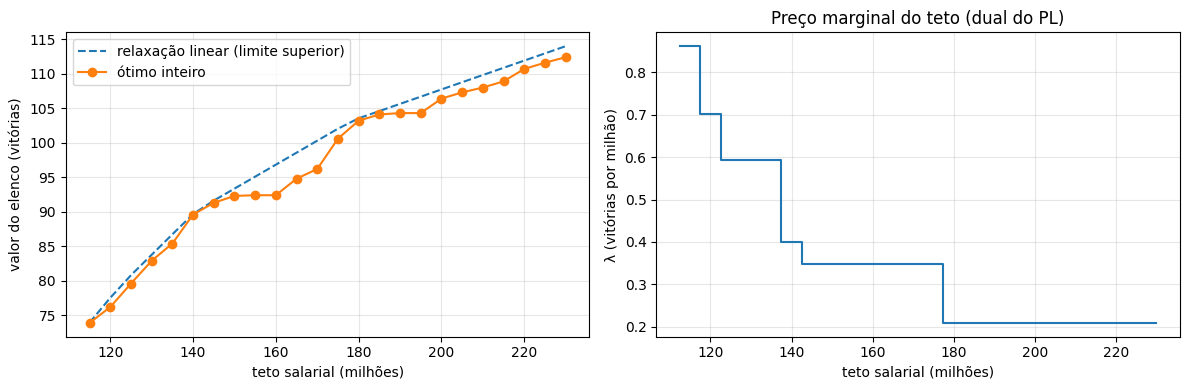

,teto,ótimo inteiro,PL,gap (%),λ
0,110,NaN,NaN,NaN,NaN
1,115,73.9,73.93,0.05,0.862
2,120,76.2,77.54,1.75,0.703
3,125,79.6,80.81,1.52,0.593
4,130,82.9,83.77,1.05,0.593
5,135,85.4,86.74,1.57,0.593
6,140,89.6,89.67,0.08,0.399
7,145,91.3,91.62,0.35,0.348
8,150,92.3,93.36,1.14,0.347
9,155,92.4,95.09,2.91,0.347


In [24]:
tetos = np.arange(110, 231, 5)
val_int, val_lp, lambdas = [], [], []
for C_ in tetos:
    pi_, *_ = modelo_etapa2(mercado, C_, **base)
    pi_.solve(solver())
    val_int.append(pulp.value(pi_.objective) if pulp.LpStatus[pi_.status] == "Optimal" else np.nan)
    pl_, *_ = modelo_etapa2(mercado, C_, relaxado=True, **base)
    pl_.solve(solver())
    ok = pulp.LpStatus[pl_.status] == "Optimal"
    val_lp.append(pulp.value(pl_.objective) if ok else np.nan)
    lambdas.append(pl_.constraints["teto"].pi if ok else np.nan)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(tetos, val_lp, "--", label="relaxação linear (limite superior)")
ax[0].plot(tetos, val_int, "o-", label="ótimo inteiro")
ax[0].set_xlabel("teto salarial (milhões)"); ax[0].set_ylabel("valor do elenco (vitórias)")
ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].step(tetos, lambdas, where="mid")
ax[1].set_xlabel("teto salarial (milhões)"); ax[1].set_ylabel("λ (vitórias por milhão)")
ax[1].set_title("Preço marginal do teto (dual do PL)"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

pd.DataFrame({"teto": tetos, "ótimo inteiro": np.round(val_int, 1), "PL": np.round(val_lp, 2),
              "gap (%)": np.round(100 * (np.array(val_lp) - np.array(val_int)) / np.array(val_int), 2),
              "λ": np.round(lambdas, 3)})

**Leitura dos resultados**
* O PL fica sempre **acima** do ótimo inteiro (é um limite superior), e o *gap* fica abaixo de 5%: a relaxação desse modelo é
  razoavelmente forte, por isso o solver resolve rápido.
* O preço marginal $\lambda$ **diminui** à medida que o teto cresce (retornos decrescentes): os primeiros milhões compram
  jogadores muito eficientes, e os seguintes compram jogadores cada vez menos eficientes.
* Para tetos muito baixos, o modelo pode ficar **inviável**: os contratos garantidos e o elenco mínimo não cabem no teto.
  É exatamente por isso que a NBA usa teto **flexível**, que é a motivação da etapa 3.
* Os valores continuam acima de 82 vitórias: o modelo da etapa 2 ainda soma o *Win Shares* de 15 jogadores como se todos
  jogassem os minutos que jogavam antes. É o que a etapa 2b corrige.

## 5. Etapa 2b – Distribuição de minutos

### 5.1 A ideia
O *Win Shares* de um jogador depende de quantos minutos ele jogou. Num time, os minutos são limitados: há 5 jogadores em
quadra durante 48 minutos, em 82 jogos, ou seja, $5 \times 48 \times 82 = 19\,680$ minutos por temporada (ignorando
prorrogações). Se o time contrata 15 jogadores que eram titulares em seus times, eles vão ter que dividir esses minutos.

Em vez de somar o *Win Shares* total, usamos a **taxa** de cada jogador:
$$r_p = \frac{\text{WS}_p}{\text{MP}_p} \quad \text{(vitórias por minuto jogado em 2025–26)}$$
e deixamos o modelo decidir **quantos minutos** cada jogador vai jogar.

### 5.2 Novos dados e variáveis
* $\text{MP}_p$: minutos jogados em 2025–26. Usamos como limite de minutos do jogador na nova temporada, uma aproximação
  da disponibilidade física e do papel que ele aguenta (um jogador que jogou 900 minutos não vira titular de 2 800).
* $k_q$: jogadores da posição $q$ em quadra ao mesmo tempo: 2 armadores, 2 alas e 1 pivô.
* $m_{pq} \ge 0$ (contínua): minutos do jogador $p$ na posição $q$ ao longo da temporada.

### 5.3 Modelo
$$
\begin{aligned}
\max \quad & \sum_{p} \sum_{q \in Q_p} r_p\, m_{pq} && \text{(vitórias esperadas)} \\
\text{s.a.} \quad & m_{pq} \le \text{MP}_p\, y_{pq} && \forall\, p,\; q \in Q_p \quad \text{(só joga se contratado e escalado em } q\text{)} \\
& \sum_{p:\, q \in Q_p} m_{pq} = k_q \cdot 48 \cdot 82 && \forall\, q \quad \text{(minutos de cada posição)} \\
& \text{todas as restrições da etapa 2}
\end{aligned}
$$

A primeira restrição é uma **ligação do tipo Big M** (slide 19): se $y_{pq} = 0$, o jogador não joga em $q$; se
$y_{pq} = 1$, ele joga no máximo $\text{MP}_p$ minutos. Aqui o "M" não é arbitrário: é o limite natural de minutos do jogador.

A segunda restrição diz que os minutos de cada posição são "ofertados" pelos jogadores e "demandados" pela partida, como no
**problema de transporte** (slide 5). Com o elenco fixo, o que sobra é um PL contínuo, que distribui os minutos dando
prioridade aos jogadores de maior taxa $r_p$.

Como $m_{pq} \le \text{MP}_p$, cada jogador contribui no máximo com o *Win Shares* que teve em 2025–26, e o total de
vitórias fica limitado pelos minutos disponíveis.

In [ ]:
def modelo_etapa2b(df, teto, por_quadra=None, **kwargs):
    por_quadra = por_quadra or {"G": 2, "F": 2, "C": 1}
    prob, x, y = modelo_etapa2(df, teto, **kwargs)
    taxa = df["valor"] / df["minutos"]
    m = {(p, q): pulp.LpVariable(f"m_{p}_{q}", lowBound=0) for (p, q) in y}

    prob.setObjective(pulp.lpSum(taxa[p] * m[p, q] for (p, q) in m))          # substitui o objetivo da etapa 2
    for (p, q) in m:                                                          # ligação Big M
        prob += m[p, q] <= df.at[p, "minutos"] * y[p, q], f"liga_{p}_{q}"
    for q, k in por_quadra.items():                                           # minutos por posição
        prob += pulp.lpSum(m[p, q2] for (p, q2) in m if q2 == q) == k * 48 * 82, f"minutos_{q}"
    return prob, x, y, m

prob2b, x2b, y2b, m2b = modelo_etapa2b(mercado, TETO, **base) #chama mpdelo
prob2b.solve(solver()) #resolve modelo
elenco2b = mostrar_elenco(mercado, x2b, y2b)
elenco2b["minutos_novos"] = [round(sum(m2b[p, q].value() for q in POSICOES if (p, q) in m2b)) for p in elenco2b.index]
elenco2b["min_por_jogo"] = (elenco2b["minutos_novos"] / 82).round(1)
elenco2b["vitorias_novas"] = (elenco2b["valor"] / elenco2b["minutos"] * elenco2b["minutos_novos"]).round(2)
print(f"Status: {pulp.LpStatus[prob2b.status]}  |  jogadores: {len(elenco2b)}  |  "
      f"folha = {elenco2b['salario'].sum():.1f}  |  vitórias esperadas = {pulp.value(prob2b.objective):.1f}")
print("Minutos distribuídos:", int(elenco2b["minutos_novos"].sum()), "de", 5 * 48 * 82)
#mostra tabela com o elenco final e as estatísticas de minutos e vitórias
elenco2b[["nome", "joga_como", "idade", "salario", "valor", "minutos", "minutos_novos", "min_por_jogo", "vitorias_novas"]]
 

Status: Optimal  |  jogadores: 13  |  folha = 164.5  |  vitórias esperadas = 72.7
Minutos distribuídos: 19680 de 19680


,nome,joga_como,idade,salario,valor,minutos,minutos_novos,min_por_jogo,vitorias_novas
49,Victor Wembanyama,C,23,16.87,10.0,1866,1866,22.8,10.00
66,Neemias Queta,C,27,2.67,9.0,1926,1926,23.5,9.00
67,Jay Huff,C,28,2.67,3.2,1719,144,1.8,0.27
47,Josh Hart,F,31,20.92,6.1,1994,1994,24.3,6.10
57,Cason Wallace,F,23,7.42,5.2,2046,2046,25.0,5.20
60,Jaime Jaquez Jr.,F,25,5.94,4.2,2121,1499,18.3,2.97
63,Brandin Podziemski,F,23,5.68,5.1,2333,2333,28.5,5.10
25,Shai Gilgeous-Alexander,G,28,40.81,15.2,2259,2259,27.5,15.20
32,Jalen Brunson,G,30,37.74,8.8,2590,2590,31.6,8.80
54,Tre Jones,G,27,8.00,5.7,1752,467,5.7,1.52


**Leitura do resultado**
* O total de vitórias agora fica abaixo de 82, num valor plausível para um time forte.
* Os jogadores de maior taxa (vitórias por minuto) recebem mais minutos; os outros completam a rotação. Alguns jogadores
  contratados podem receber poucos minutos: eles estão no elenco para cumprir as regras (tamanho, posições, veteranos,
  contratos garantidos), mas o modelo prefere não usá-los.
* O elenco escolhido pode ser diferente do da etapa 2: um jogador com muitos *Win Shares* acumulados, mas taxa baixa,
  perde atratividade quando os minutos passam a ser disputados.

### 5.4 Limitações desta versão
* A taxa $r_p$ é tratada como constante: na prática, a eficiência cai quando o jogador joga mais minutos ou divide a bola
  com outros astros.
* $\text{MP}_p$ como limite penaliza jogadores que perderam a temporada por lesão, mesmo que estejam saudáveis agora.
* O modelo distribui minutos da temporada inteira, não de cada jogo (não há rodízio de quintetos nem descanso em
  sequências de jogos).

## 6. Comparação entre as etapas

In [26]:
pd.DataFrame([
    {"etapa": "1 – mochila", "jogadores": len(sel1), "folha": round(folha1, 1), "valor": round(valor1, 1)},
    {"etapa": "2 – composição", "jogadores": len(elenco), "folha": round(elenco["salario"].sum(), 1),
     "valor": round(elenco["valor"].sum(), 1)},
    {"etapa": "2b – minutos", "jogadores": len(elenco2b), "folha": round(elenco2b["salario"].sum(), 1),
     "valor": round(pulp.value(prob2b.objective), 1)},
])

,etapa,jogadores,folha,valor
0,1 – mochila,20,163.6,109.5
1,2 – composição,15,163.8,94.8
2,2b – minutos,13,164.5,72.7


O valor cai da etapa 1 para a 2 porque o modelo ganhou restrições realistas. Esse é o **custo das regras**: a etapa 1
era um limite otimista, não um elenco possível. Na etapa 2b, o valor cai de novo, agora para um número compatível com uma
temporada de 82 jogos, porque os minutos deixam de ser contados em dobro.

## 7. Limitações e próximos passos (rascunho da discussão)

**Limitações do modelo atual**
* **Valor aditivo:** nas etapas 1 e 2, somar o valor de 15 jogadores supõe que todos jogam os mesmos minutos de antes. A
  etapa 2b corrige isso com a distribuição de minutos, mas ainda supõe eficiência constante por minuto.
* **Win Shares como previsão:** o *Win Shares* da temporada anterior erra com lesões, envelhecimento e troca de time, e a
  parte defensiva da métrica depende muito da defesa do time como um todo.
* **Encaixe entre jogadores:** dois armadores dominantes podem render menos juntos do que separados. Modelar isso exige
  termos $x_a x_b$ (quadráticos), que podem ser linearizados com uma variável auxiliar e restrições lógicas.
* **Incerteza:** $v_p$ é uma previsão. Uma versão com risco maximiza $\mathbb{E}[\text{valor}] - \gamma\,\text{Var}$, um
  **QP inteiro** parecido com a carteira de Markowitz (slide 12).
* **Mercado:** o modelo supõe que todo jogador listado aceita assinar pelo salário informado.

**Etapas seguintes**
* **Etapa 3 – teto flexível:** permitir passar do teto pagando imposto de luxo progressivo por faixas, ou seja, um custo
  convexo e linear por partes (slide 4), modelado com variáveis por faixa ou SOS2 (slide 22). Os *aprons* entram como
  restrições se-então com Big M (slide 19).
* **Etapa 4 – várias temporadas:** contratos plurianuais, salários e valores que mudam com a idade (planejamento
  multiperíodo, slide 4).